# Hindi TinyStories GPT (decoder-only, your own model code)

Trains the GPT you wrote (`my_gpt.py`, pasted verbatim in the model cell) on ~100M tokens of Hindi children's stories.
Run the cells top to bottom. Runtime: **GPU, L4 preferred** (see PROJECT.md). Re-running after a disconnect resumes from Google Drive.

Cell map: 1 setup, 2 config, 3 data download, 4 tokenizer, 5 your model, 6 helpers, 7 training loop, 8 train, 9 plots, 10 sampling, 11-13 experiments.

In [10]:
# 1. Setup: installs, device, precision, Google Drive for checkpoints
!pip -q install sentencepiece

import os, math, time, json, codecs, itertools, contextlib
import numpy as np, requests, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# Precision. bf16 autocast needs compute capability >= 8 (L4, A100). The T4 (7.5) has no bf16, and fp16 is NOT an
# option here: your attention does masked_fill(..., -1e9), which overflows fp16 and raises an error. So T4 runs fp32.
amp_dtype = torch.bfloat16 if device == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else None
def autocast():
    return torch.autocast(device_type=device, dtype=amp_dtype, enabled=amp_dtype is not None)

# Checkpoints and tokenised data live on Drive so they survive a disconnect.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT, WORK = "/content/drive/MyDrive/hindi_gpt", "/content"
except ImportError:                      # running somewhere that is not Colab
    ROOT, WORK = "./hindi_gpt", "./work"
os.makedirs(ROOT, exist_ok=True); os.makedirs(WORK, exist_ok=True)

print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "", "| precision:", amp_dtype or "fp32")
print("torch", torch.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda NVIDIA L4 | precision: torch.bfloat16
torch 2.11.0+cu128


In [11]:
# 2. Config. d_ff is about 8/3 * d_model, rounded to a multiple of 64.
N_STORIES = 400_000          # stories to download (about 1.1 GB, about 100M tokens)
VOCAB = 8000                 # BPE vocab size
cfg = dict(vocab_size=VOCAB, d_model=512, num_heads=8, d_ff=1344, num_layers=8, max_seq_len=512)
tcfg = dict(batch_size=32, steps=12000, lr=6e-4, min_lr=6e-5, warmup=300,
            weight_decay=0.1, grad_clip=1.0, eval_every=500, sample_every=2000, ckpt_every=1000)
print(f"ln(vocab) = {math.log(VOCAB):.3f}   tokens per step = {tcfg['batch_size'] * cfg['max_seq_len']:,}"
      f"   total tokens = {tcfg['batch_size'] * cfg['max_seq_len'] * tcfg['steps'] / 1e6:.0f}M")

ln(vocab) = 8.987   tokens per step = 16,384   total tokens = 197M


In [12]:
# 3. Data: stream the first N_STORIES stories (Apache-2.0, GPT-4o-mini-written Hindi TinyStories), one story per line.
# We stream the JSON array and stop early, so we never download the whole 2M-story file.
URL = "https://huggingface.co/datasets/TinyStories-Regional/hindi-generated_4o-mini_2M/resolve/main/train.json"
TXT = f"{WORK}/stories.txt"
TOK_DONE = f"{ROOT}/tokens_val.npy"          # written last, so its presence means tokenisation finished

def stream_stories(n):
    dec, utf8, buf, got = json.JSONDecoder(), codecs.getincrementaldecoder("utf-8")(), "", 0
    with requests.get(URL, stream=True, timeout=60) as r:
        r.raise_for_status()
        for chunk in r.iter_content(1 << 20):
            buf += utf8.decode(chunk); pos = 0
            while (i := buf.find("{", pos)) >= 0:
                try: obj, pos = dec.raw_decode(buf, i)
                except json.JSONDecodeError: break          # object is split across chunks: read more
                yield " ".join(obj["story"].split())         # collapse whitespace/newlines
                got += 1
                if got >= n: return
            buf = buf[pos:]

if not os.path.exists(TOK_DONE) and not os.path.exists(TXT):
    t0 = time.time()
    with open(TXT + ".tmp", "w", encoding="utf-8") as f:
        for k, s in enumerate(stream_stories(N_STORIES)):
            f.write(s + "\n")
            if k % 50_000 == 0: print(f"{k:,} stories, {time.time() - t0:.0f}s")
    os.replace(TXT + ".tmp", TXT)
    print("downloaded in", round(time.time() - t0), "s")
else:
    print("data already prepared, skipping download")

0 stories, 2s
50,000 stories, 4s
100,000 stories, 7s
150,000 stories, 9s
200,000 stories, 11s
250,000 stories, 14s
300,000 stories, 16s
350,000 stories, 18s
downloaded in 21 s


In [13]:
# 4. Tokenizer: BPE (SentencePiece), trained on the first 20k stories, then encode everything to uint16 ids.
# Same algorithm as your CS336 BPE; we use the fast library version because pure-Python BPE training is slow.
import sentencepiece as spm
SP_PREFIX = f"{ROOT}/hi_bpe"
N_VAL = 2000                                  # last 2000 stories = validation set

if not os.path.exists(SP_PREFIX + ".model"):
    with open(f"{WORK}/sp_train.txt", "w", encoding="utf-8") as out, open(TXT, encoding="utf-8") as f:
        out.writelines(itertools.islice(f, 20_000))
    spm.SentencePieceTrainer.train(input=f"{WORK}/sp_train.txt", model_prefix=SP_PREFIX, vocab_size=VOCAB,
        model_type="bpe", character_coverage=1.0, byte_fallback=True,
        unk_id=0, eos_id=1, bos_id=-1, pad_id=-1, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file=SP_PREFIX + ".model")
EOS = sp.eos_id()
assert sp.get_piece_size() == VOCAB

if not os.path.exists(TOK_DONE):
    lines = open(TXT, encoding="utf-8").read().splitlines()
    parts, t0 = [], time.time()
    for i in range(0, len(lines), 5000):
        for ids in sp.encode(lines[i:i + 5000], add_eos=True):    # EOS marks the end of each story
            parts.append(np.asarray(ids, dtype=np.uint16))
    train_ids, val_ids = np.concatenate(parts[:-N_VAL]), np.concatenate(parts[-N_VAL:])
    np.save(f"{ROOT}/tokens_train.npy", train_ids); np.save(TOK_DONE, val_ids)
    del lines, parts
    print(f"tokenised in {time.time() - t0:.0f}s")

train_data, val_data = np.load(f"{ROOT}/tokens_train.npy"), np.load(TOK_DONE)
print(f"train tokens {len(train_data) / 1e6:.1f}M | val tokens {len(val_data) / 1e6:.2f}M | vocab {VOCAB}")
s = open(TXT, encoding="utf-8").readline()[:120] if os.path.exists(TXT) else sp.decode(train_data[:60].tolist())
print("example:", s); print("tokens :", sp.encode(s)[:12], "| round trip ok:", sp.decode(sp.encode(s)) == s)

tokenised in 24s
train tokens 102.2M | val tokens 0.51M | vocab 8000
example: एक बार की बात है, एक छोटे से गाँव में एक प्यारा सा खरगोश रहता था। उसका नाम था चीकू। चीकू बहुत ही रोमांचक कारनामे करने का
tokens : [268, 382, 300, 377, 295, 7873, 268, 413, 301, 366, 287, 268] | round trip ok: True


In [14]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def swiglu(x,W1,W2,W3):
  gate = W1(x)*torch.sigmoid(W1(x)) #silu W1(x)
  #W1,W3 are of size B,T,d_ff where d_ff ->8d/3 (thumb rule) d is d_mode
  value = W3(x) #value


  return W2(gate*value)

def rmsnorm(x,weights,eps=1e-5):

  mean_sq = (x * x).mean(dim=-1,keepdim = True)
  rms = torch.sqrt(mean_sq+eps)

  x_norm = x / rms
  y = x_norm * weights #RMS norm weights

  return y


import math
import torch
import torch.nn as nn


class MultiheadAttentionwithRoPE(nn.Module):
  def __init__(self,d_model,num_heads,theta=10000.0):
    super().__init__()

    assert d_model % num_heads == 0
    self.num_heads = num_heads
    self.d_model = d_model
    self.theta = theta

    self.d_in = d_model
    self.d_k = d_model
    self.d_v = d_model

    self.d_k_head = d_model // num_heads
    self.d_v_head = d_model // num_heads

    # weights

    self.W_q = nn.Linear(self.d_in,self.d_k,bias=False)
    self.W_k = nn.Linear(self.d_in,self.d_k,bias=False)
    self.W_v = nn.Linear(self.d_in,self.d_k,bias=False)
    self.W_o = nn.Linear(self.d_v,self.d_model,bias=False)

  def rope(self,x,token_positions):

    d_k = x.shape[-1];
    #split into pairs (even dims, odd dims)
    # (B, H, T, d_k/2)
    # TELLING THE last dimension start from 0 skip 2 and start from 1 skip 2
    x_even = x[...,0::2] # (B, H, T, d_k/2)
    x_odd  = x[...,1::2] # (B, H, T, d_k/2)

    # 2) frequency for each pair index: theta^(-2j/d_k)

    j = torch.arange(d_k//2 , device = x.device ,dtype = torch.float32)  # (d_k/2,) [0 1 2 3 ... d_k//2]
    theta_j = self.theta ** (-2.0 * j / d_k)  # (d_k/2,)

    pos = token_positions.to(torch.float32)[..., None]   # (T, 1) or (B, T, 1)
    angles = pos * theta_j      # (T, d_k/2) or (B, T, d_k/2) -> (T,1) * (theta * (-2j/d) {j -> [0 1 2  d_k//2]})

    cos = torch.cos(angles).to(x.dtype) # B,T,d_k//2
    sin = torch.sin(angles).to(x.dtype) # B,T,d_k//2

    while cos.ndim < x_even.ndim:  #(B,T,d/2) -> #B,1,T,d/2
      cos = cos.unsqueeze(-3)
      sin = sin.unsqueeze(-3)

    y_even = x_even * cos - x_odd * sin # B,H,T,d/2 * B,1,T,d/2
    y_odd  = x_even * sin + x_odd * cos

    y = torch.empty_like(x)   # (B, H, T, d_k) (create a empty array of size of x)
    y[..., 0::2] = y_even
    y[..., 1::2] = y_odd
    return y

  def forward(self,in_features,token_positions=None):
    B,T,d_in = in_features.shape; # shape is an attribute not a method so no brackets

    #projects

    #W_q is (d_model , d_in) -> W_q * x(B,T,d_in) > Q -> B,T,d_model
    Q = self.W_q(in_features) # W*x
    K = self.W_k(in_features)
    V = self.W_v(in_features)

    # we get B,T,d_model -> B,T,H,d_k -> tranpose->B,H,T,d_k
    # dividing Q,K,V projections for different heads
    Q = Q.view(B,T ,self.num_heads,self.d_k_head).transpose(1,2);
    K = K.view(B,T ,self.num_heads,self.d_k_head).transpose(1,2);
    V = V.view(B,T ,self.num_heads,self.d_v_head).transpose(1,2);

     # RoPE on Q and K only (not V)
     #(if None then u are giving 0 to T-1 already)
    if token_positions is None:
      token_positions = torch.arange(T, device=in_features.device)   # (T,)

    Q = self.rope(Q, token_positions)
    K = self.rope(K, token_positions)

    #SDPA

    scores = Q @ K.transpose(-2,-1) #B,H,T,D_K * B,H,d_k,T -> B,H,T,T
    normalized_scores = scores / math.sqrt(self.d_k_head)

    causal_mask = torch.tril(torch.ones(T,T,device = in_features.device ,dtype=torch.bool)) #T,T
    normalized_scores = normalized_scores.masked_fill(~causal_mask,-1e9) #B,H,T,T
    weights = normalized_scores.softmax(dim=-1)
    heads = weights @ V #B,H,T,T * B,H,T,d_k -> B,H,T,d_k

    mha = heads.transpose(1,2).reshape(B,T,self.num_heads*self.d_v_head) #b,h,t,d_k -> b,t,h,d_k -> b,t,d_v (go from left to right)
    out = self.W_o(mha) #B,T,d_model * B,T,d_v -> #B,T,d_model

    return out



class TransformerBlock(nn.Module):
  def __init__(self,d_model,num_heads,d_ff,theta = 10000.0):
    super().__init__()


    #attn
    self.attn = MultiheadAttentionwithRoPE(d_model,num_heads,theta)
    # pre norm attn
    self.norm1_w = nn.Parameter(torch.ones(d_model))
    self.theta = theta


   #  SwiGlu
    self.W1 = nn.Linear(d_model,d_ff,bias=False)
    self.W3 = nn.Linear(d_model,d_ff,bias = False)

    self.W2 = nn.Linear(d_ff,d_model,bias = False)

    self.norm2_w = nn.Parameter(torch.ones(d_model))

  def forward(self,x,token_positions=None):

    residual = x
    x_rms = rmsnorm(x,self.norm1_w)
    attn_x = self.attn(x_rms,token_positions)

    x = residual + attn_x

    residual = x

    x_rms_1 = rmsnorm(x,self.norm2_w)
    x_swiglu = swiglu(x_rms_1,self.W1,self.W2,self.W3)

    x = residual + x_swiglu

    return x




import torch.nn.functional as F

class GPT(nn.Module):
  def __init__(self,vocab_size,max_seq_len,num_layers,d_model,num_heads,d_ff,theta = 10000.0):
    super().__init__()

    self.max_seq_len = max_seq_len

    self.emb_tokens = nn.Embedding(vocab_size,d_model)
    self.blocks = nn.ModuleList(
        [TransformerBlock(d_model,num_heads,d_ff,theta) for _ in range(num_layers)]
    )


    self.norm_final_weights = nn.Parameter(torch.ones(d_model))
    self.lm_head = nn.Linear(d_model,vocab_size,bias=False)

  def forward(self,token_ids,targets = None,token_position = None):
    B,T  = token_ids.shape
    x = self.emb_tokens(token_ids)

    for block in self.blocks:
      x = block(x) # default token positions go 0,1,.. T-1 in the MHA code present

    x = rmsnorm(x,self.norm_final_weights)

    logits = self.lm_head(x)

    #Training code
    loss = None

    if targets is not None:
      pred = logits[:,:-1,:]  #B,T-1,V (vocab-size)
      true = targets[:,1:] #B,T-1 (next token pred)

      loss = F.cross_entropy(pred.reshape(-1,pred.shape[-1]),true.reshape(-1)) # loss between pred of the next token and the true has the next token

    return logits,loss

  @torch.no_grad()

  def generate(self,token_ids,n_new):
    for _ in range(n_new):
      context = token_ids[:,-self.max_seq_len:]
      logits,_ = self(context) #B,T,vocab_size

      last = logits[:,-1,:] #(B,vocab_size) last word only

      probs = last.softmax(dim=-1)
      next_id = torch.multinomial(probs,num_samples=1) #B,1 picsk index at random where each index chance is its probability
      #for greedy last.argmax(dim=-1,keepdim=True)
      token_ids = torch.cat([token_ids,next_id],dim=1) # B, T+1

    return token_ids


In [15]:
# 6. Helpers: batches, LR schedule, evaluation, sampling
def get_batch(data, B, T):
    ix = np.random.randint(0, len(data) - T, size=B)             # B random windows of T tokens
    return torch.from_numpy(np.stack([data[i:i + T] for i in ix]).astype(np.int64)).to(device)

def lr_at(step, total, tc):                                       # linear warmup, then cosine decay to min_lr
    if step < tc["warmup"]: return tc["lr"] * (step + 1) / tc["warmup"]
    p = min(1.0, (step - tc["warmup"]) / max(1, total - tc["warmup"]))
    return tc["min_lr"] + 0.5 * (1 + math.cos(math.pi * p)) * (tc["lr"] - tc["min_lr"])

@torch.no_grad()
def evaluate(model, data, B=32, max_batches=40):
    """Mean next-token cross-entropy on the validation set (perplexity = exp of it)."""
    model.eval(); T = model.max_seq_len
    rows = len(data) // T
    X = data[:rows * T].reshape(rows, T)                          # fixed non-overlapping windows
    losses = []
    for i in range(0, min(rows, B * max_batches), B):
        x = torch.from_numpy(X[i:i + B].astype(np.int64)).to(device)
        with autocast(): _, loss = model(x, x)                    # targets are the inputs; the model shifts them
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

@torch.no_grad()
def sample(model, prompt, n_new=150, temperature=0.8, top_k=40):
    """temperature=0 means greedy. top_k keeps only the k most likely tokens before sampling."""
    model.eval()
    ids = torch.tensor([sp.encode(prompt)], device=device)
    for _ in range(n_new):
        with autocast(): logits, _ = model(ids[:, -model.max_seq_len:])
        logits = logits[:, -1, :].float()
        if temperature == 0: nxt = logits.argmax(-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k: logits[logits < torch.topk(logits, top_k).values[:, [-1]]] = -float("inf")
            nxt = torch.multinomial(logits.softmax(-1), 1)
        if nxt.item() == EOS: break
        ids = torch.cat([ids, nxt], dim=1)
    model.train()
    return sp.decode(ids[0].tolist())

PROMPTS = ["एक बार की बात है", "राहुल अपनी माँ के साथ", "जंगल में एक छोटी सी चिड़िया"]

In [16]:
# 7. Training loop (AdamW, warmup + cosine LR, grad clipping, periodic eval / sample / checkpoint)
def make_model(cfg):
    return GPT(**cfg).to(device)

def train(cfg, tc, tag, make=make_model, resume=True, verbose=True, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)                  # same init and batches across experiments
    model = make(cfg)
    decay = [p for p in model.parameters() if p.ndim >= 2]        # matrices get weight decay; norm gains do not
    no_decay = [p for p in model.parameters() if p.ndim < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": tc["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}],
                            lr=tc["lr"], betas=(0.9, 0.95), fused=(device == "cuda"))
    T, B, total = cfg["max_seq_len"], tc["batch_size"], tc["steps"]
    hist = dict(step=[], train=[], val=[], val_step=[], lr=[]); start = 0
    ck = f"{ROOT}/{tag}.pt"
    if resume and os.path.exists(ck):                              # resume after a Colab disconnect
        s = torch.load(ck, map_location=device)
        model.load_state_dict(s["model"]); opt.load_state_dict(s["opt"]); hist, start = s["hist"], s["step"]
        print(f"resumed {tag} from step {start}")
    n_params = sum(p.numel() for p in model.parameters())
    if verbose: print(f"{tag}: {n_params / 1e6:.1f}M params, {total} steps, {B * T:,} tokens/step")

    if start == 0:
        hist["val_step"].append(0); hist["val"].append(evaluate(model, val_data))
        if verbose: print(f"step 0 | val loss {hist['val'][-1]:.3f}  (ln vocab = {math.log(cfg['vocab_size']):.3f})")
    t0, acc, n_acc = time.time(), torch.zeros((), device=device), 0
    for step in range(start, total):
        lr = lr_at(step, total, tc)
        for g in opt.param_groups: g["lr"] = lr
        x = get_batch(train_data, B, T)
        with autocast(): _, loss = model(x, x)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), tc["grad_clip"])
        opt.step()
        acc += loss.detach(); n_acc += 1
        done = step + 1
        if done % 100 == 0 or done == total:
            hist["step"].append(done); hist["train"].append((acc / n_acc).item()); hist["lr"].append(lr); acc.zero_(); n_acc = 0
            if verbose and (done % 200 == 0 or done == total):
                el = time.time() - t0; tps = (done - start) * B * T / el
                print(f"step {done:5d} | train {hist['train'][-1]:.3f} | lr {lr:.2e} | gnorm {gnorm:.2f} | {tps / 1e3:.0f}k tok/s | "
                      f"{el / 60:.1f} min | eta {(total - done) * B * T / tps / 60:.1f} min")
        if done % tc["eval_every"] == 0 or done == total:
            hist["val_step"].append(done); hist["val"].append(evaluate(model, val_data))
            if verbose: print(f"           val loss {hist['val'][-1]:.3f} | perplexity {math.exp(hist['val'][-1]):.1f}")
        if verbose and done % tc["sample_every"] == 0:
            print("  sample:", sample(model, PROMPTS[0])[:300].replace("\n", " "))
        if resume and (done % tc["ckpt_every"] == 0 or done == total):
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), step=done, hist=hist, cfg=cfg), ck + ".tmp")
            os.replace(ck + ".tmp", ck)
    return model, hist

In [17]:
# 8. Train. Check the first lines: step-0 val loss should be close to ln(vocab) (about 9.0 for vocab 8000).
model, hist = train(cfg, tcfg, tag="main")

main: 33.1M params, 12000 steps, 16,384 tokens/step
step 0 | val loss 9.136  (ln vocab = 8.987)
step   200 | train 2.975 | lr 4.00e-04 | gnorm 0.45 | 34k tok/s | 1.6 min | eta 94.2 min
step   400 | train 1.835 | lr 6.00e-04 | gnorm 0.37 | 34k tok/s | 3.2 min | eta 92.6 min
           val loss 1.559 | perplexity 4.8
step   600 | train 1.517 | lr 5.99e-04 | gnorm 0.35 | 34k tok/s | 4.9 min | eta 92.6 min
step   800 | train 1.378 | lr 5.98e-04 | gnorm 0.34 | 34k tok/s | 6.5 min | eta 90.5 min
step  1000 | train 1.290 | lr 5.95e-04 | gnorm 0.35 | 34k tok/s | 8.1 min | eta 88.7 min
           val loss 1.269 | perplexity 3.6
step  1200 | train 1.242 | lr 5.92e-04 | gnorm 0.34 | 34k tok/s | 9.8 min | eta 87.8 min
step  1400 | train 1.200 | lr 5.88e-04 | gnorm 0.34 | 34k tok/s | 11.4 min | eta 85.9 min
           val loss 1.168 | perplexity 3.2
step  1600 | train 1.173 | lr 5.84e-04 | gnorm 0.32 | 34k tok/s | 13.0 min | eta 84.7 min
step  1800 | train 1.138 | lr 5.78e-04 | gnorm 0.33 | 34k tok

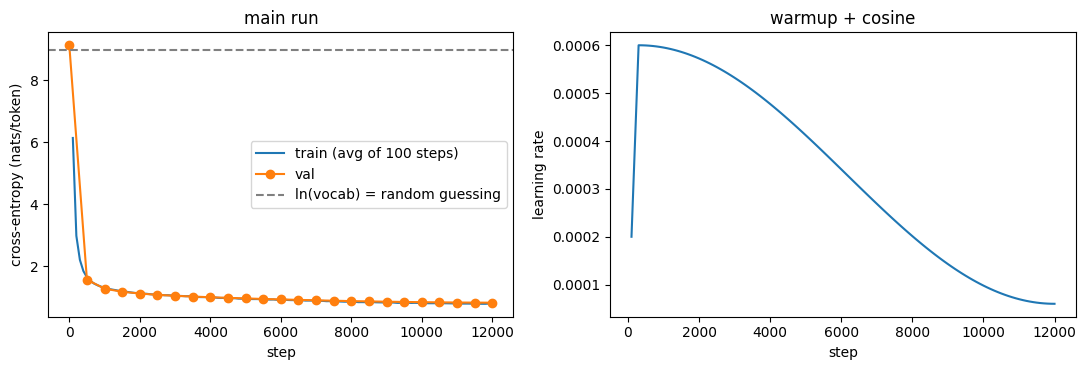

final val loss 0.814 -> perplexity 2.3 per token


In [18]:
# 9. Loss curves and perplexity
def plot_run(hist, V, title="main run"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist["step"], hist["train"], label="train (avg of 100 steps)")
    ax[0].plot(hist["val_step"], hist["val"], "o-", label="val")
    ax[0].axhline(math.log(V), color="gray", ls="--", label="ln(vocab) = random guessing")
    ax[0].set(xlabel="step", ylabel="cross-entropy (nats/token)", title=title); ax[0].legend()
    ax[1].plot(hist["step"], hist["lr"]); ax[1].set(xlabel="step", ylabel="learning rate", title="warmup + cosine")
    plt.tight_layout(); plt.savefig(f"{ROOT}/{title.replace(' ', '_')}.png", dpi=120); plt.show()
plot_run(hist, VOCAB)
print(f"final val loss {hist['val'][-1]:.3f} -> perplexity {math.exp(hist['val'][-1]):.1f} per token")

In [19]:
# 10. Sampling. First your own generate() (pure multinomial, temperature 1, no top-k), then our sampler with knobs.
model.eval()
ids = torch.tensor([sp.encode(PROMPTS[0])], device=device)
with autocast(): out = model.generate(ids, 120)
print("your generate():", sp.decode(out[0].tolist()), "\n")

for temp, k in [(0, None), (0.5, 40), (0.8, 40), (1.0, None), (1.5, None)]:
    print(f"--- temperature {temp}, top_k {k}")
    print(sample(model, PROMPTS[0], n_new=150, temperature=temp, top_k=k), "\n")

your generate(): एक बार की बात है, एक प्यारे से गाँव में एक चमगादड़ रहता था। उसका नाम था चम्पू। चम्पू बहुत ही प्यारा और मजेदार था। वह हमेशा अपने दोस्तों के साथ खेलता और नई-नई बातें करता। चम्पू का एक सपना था, वह चाहता था कि वह आसमान में उड़ सके। एक दिन, चम्पू ने सोचा कि क्यों न वह अपने सपने को पूरा करने की कोशिश करे। उसने अपने दोस्तों से कहा, "मैं उड़ने में बहुत अच्छा करना चाहता हूँ!" उसके दोस्तों ने उसे उत्साहवर्धक शब्दों में कहा, "तुम जरूर कर सकते हो, चम्पू!" चम्पू ने अपने पंखों को फैलाया और एक ऊँचे पेड़ पर चढ़ गया 

--- temperature 0, top_k None
एक बार की बात है, एक छोटे से गाँव में एक प्यारा सा बच्चा था जिसका नाम था मोहन। मोहन को खेलना बहुत पसंद था। एक दिन, उसने अपने दोस्तों के साथ मिलकर एक खेल खेलने का सोचा। उन्होंने एक बड़ा सा मैदान चुना और वहाँ खेलने लगे। खेल के दौरान, मोहन ने देखा कि उसके दोस्तों के हाथ गंदे हो गए हैं। उसने सोचा, "हमें अपने हाथ धोने चाहिए।" मोहन ने अपने दोस्तों से कहा, "चलो, हम अपने हाथ धोते हैं और फिर खेलते हैं।" सभी दोस्त मोहन की बात मान गए। उन्होंने अपने हाथ 

## Experiments (each is a short fresh run on the same config)
Each run trains from scratch for `EXP_STEPS` steps and compares against the baseline run. None of these edit your model code:
the variants switch a feature off from outside (see the next cell). Hypotheses and what to look for are in PROJECT.md.

In [20]:
# 11. Variants. Each one switches off or swaps a single piece, without editing the model cell above.
import math as _real_math

class _NoScaleMath:                       # attention calls math.sqrt(d_k_head); this makes it return 1.0 (no 1/sqrt(d) scaling)
    sqrt = staticmethod(lambda x: 1.0)
    def __getattr__(self, k): return getattr(_real_math, k)

class PostNormBlock(TransformerBlock):    # post-norm: normalise AFTER the residual add (original Transformer layout)
    def forward(self, x, token_positions=None):
        x = rmsnorm(x + self.attn(x, token_positions), self.norm1_w)
        return rmsnorm(x + swiglu(x, self.W1, self.W2, self.W3), self.norm2_w)

@contextlib.contextmanager
def patched(name):
    g = globals(); saved = (torch.tril, g["math"], MultiheadAttentionwithRoPE.rope)
    if name == "no_mask":  torch.tril = lambda t: t                                  # mask becomes all True: every token sees the future
    if name == "no_scale": g["math"] = _NoScaleMath()
    if name == "no_rope":  MultiheadAttentionwithRoPE.rope = lambda self, x, pos: x  # no positional signal at all
    try: yield
    finally: torch.tril, g["math"], MultiheadAttentionwithRoPE.rope = saved

def make_post_norm(cfg):
    m = GPT(**cfg)
    m.blocks = nn.ModuleList([PostNormBlock(cfg["d_model"], cfg["num_heads"], cfg["d_ff"]) for _ in range(cfg["num_layers"])])
    return m.to(device)

In [21]:
# 12. Run the experiments. Edit EXP_STEPS (1500 is enough to see the effects, 2000 is cleaner).
EXP_STEPS = 2000
etc = dict(tcfg, steps=EXP_STEPS, warmup=100, eval_every=250, sample_every=10**9)    # sampling is done at the end instead
results = {}

def run_exp(name, variant=None, heads=None, make=make_model):
    c = dict(cfg, num_heads=heads) if heads else cfg
    t0 = time.time()
    with patched(variant):
        m, h = train(c, etc, tag=name, make=make, resume=False, verbose=False)
        h["sample"] = sample(m, PROMPTS[0], n_new=100)
    if variant == "no_mask":                              # the honest number: same weights, mask switched back on
        h["val_masked"] = evaluate(m, val_data)
    results[name] = h
    print(f"{name:12s} final val {h['val'][-1]:.3f} | train {h['train'][-1]:.3f} | {(time.time() - t0) / 60:.1f} min")
    print("   sample:", h["sample"][:200].replace("\n", " "), "\n")

run_exp("baseline")
run_exp("no_mask", "no_mask")
run_exp("no_scale", "no_scale")
run_exp("no_rope", "no_rope")
run_exp("post_norm", make=make_post_norm)
run_exp("heads_2", heads=2)
run_exp("heads_16", heads=16)      # 32 heads = 4x the attention memory of 8 heads: OOM on an L4

baseline     final val 1.078 | train 1.082 | 16.7 min
   sample: एक बार की बात है, एक छोटे से गाँव में एक प्यारा सा बच्चा था जिसका नाम था मोहन। मोहन को लिखना बहुत पसंद था। वह हमेशा अपने सपनों के साथ बैठा रहता था। एक दिन, उसने सोचा कि वह अपने दोस्तों के लिए एक कहानी 

no_mask      final val 0.001 | train 0.000 | 16.9 min
   sample: एक बार की बात है है है है है है है है है है है है है है है है हैकककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककककक 

no_scale     final val 1.141 | train 1.146 | 16.7 min
   sample: एक बार की बात है, एक छोटे से गाँव में एक प्यारा सा बच्चा था जिसका नाम मोहन था। मोहन को खाना बनाना बहुत पसंद था। एक दिन, उसकी माँ ने उसे एक खास मिठाई बनाने के लिए कहा। मोहन ने खुशी-खुशी चम्मच लिया और म 

no_rope      final val 1.107 | train 1.116 | 16.0 min
   sample: एक बार की बात है, एक छोटे से गाँव में एक प्यारा सा बच्चा था जिसका नाम मोहन था। मोहन को दौड़ना बहुत पसंद था। वह हमेशा अपने दोस्तों के साथ दौड़ने के लिए बाहर जाता था। एक दिन, मोहन और उस

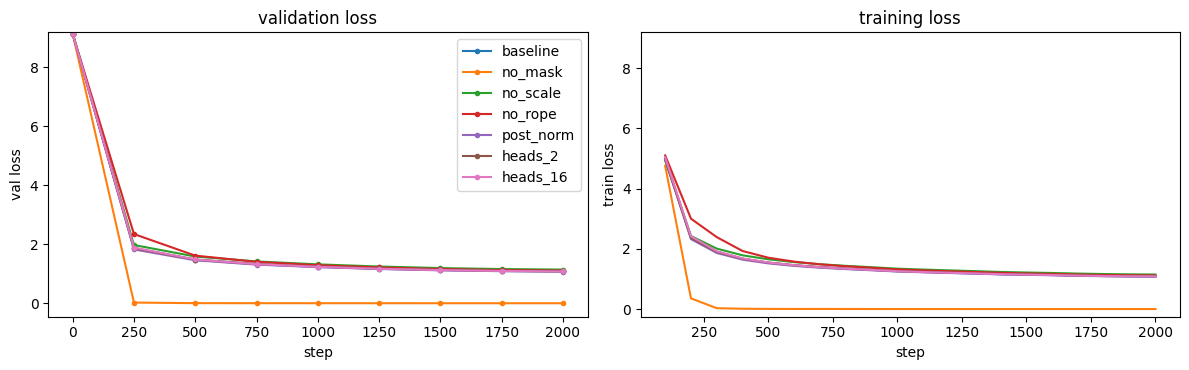

baseline     val 1.078  train 1.082
no_mask      val 0.001  train 0.000  | val with mask restored 12.260
no_scale     val 1.141  train 1.146
no_rope      val 1.107  train 1.116
post_norm    val 1.072  train 1.077
heads_2      val 1.085  train 1.089
heads_16     val 1.078  train 1.084


In [22]:
# 13. Compare. Lower val loss is better; baseline is the reference.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in results.items():
    ax[0].plot(h["val_step"], h["val"], "o-", ms=3, label=name)
    ax[1].plot(h["step"], h["train"], label=name)
ax[0].set(xlabel="step", ylabel="val loss", title="validation loss"); ax[0].set_ylim(top=math.log(VOCAB) + 0.2); ax[0].legend()
ax[1].set(xlabel="step", ylabel="train loss", title="training loss"); ax[1].set_ylim(top=math.log(VOCAB) + 0.2)
plt.tight_layout(); plt.savefig(f"{ROOT}/experiments.png", dpi=120); plt.show()
for name, h in results.items():
    extra = f"  | val with mask restored {h['val_masked']:.3f}" if "val_masked" in h else ""
    print(f"{name:12s} val {h['val'][-1]:.3f}  train {h['train'][-1]:.3f}{extra}")

In [ ]:
# 14. Publish code, results and logs to GitHub (token comes from the GITHUB_KEY Colab secret)
%run -i /content/finalize.py
build()
push()